# demprepfly usage examples

Examples using the test data: a 50 cm DEM of a glacier surface with moulins in swiss LV95 (EPSG:2056) and a shapefile with manually drawn moulin outlines.

All distances (`detect_maxsize`, `smoothing_radius`, ...) are given in coordinate units of the DEM, here meters.

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


Text(0.5, 1.0, 'original DEM')

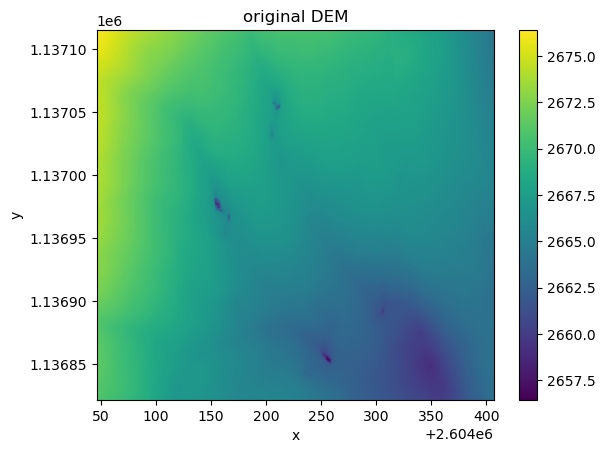

In [2]:
from matplotlib import pyplot as plt
from rioxarray import open_rasterio

from demprepfly import prep_dem, reproj_dem, detect_crevasses, inpaint_dem

dem_tif = 'test_data/dem_moulins_50cm_LV95.tif'
moulin_shp = 'test_data/moulin_mask.shp'

dem_orig = open_rasterio(dem_tif, masked=True).sel(band=1)
dem_orig.plot()
plt.title('original DEM')

## 1. Fill moulins from a shapefile and smooth

`prep_dem` returns the prepared DEM and a mask of all filled pixels, both as georeferenced xarray DataArrays.

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


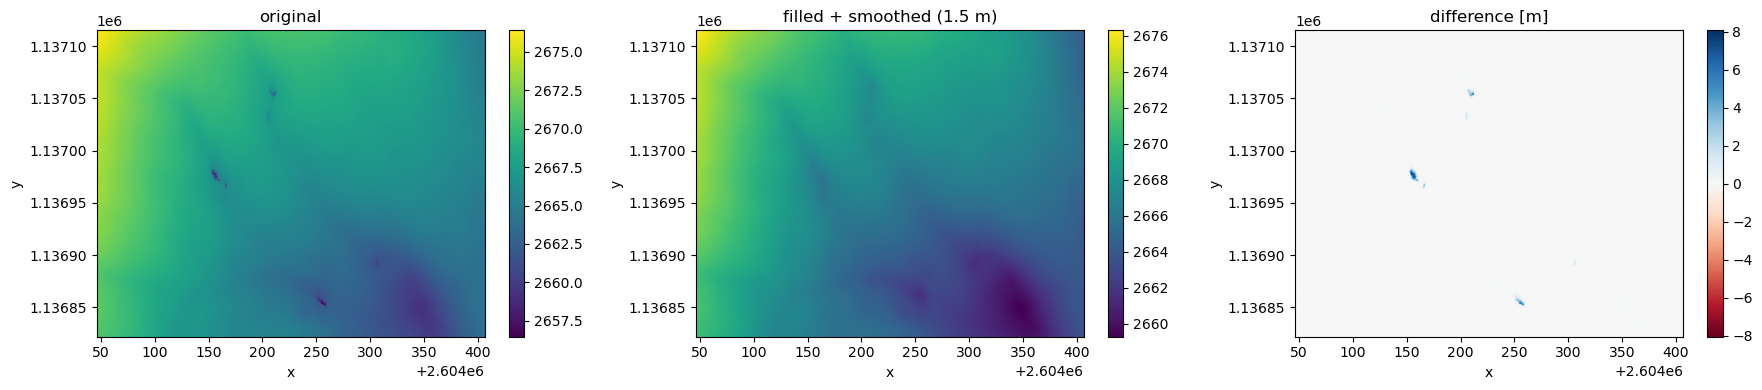

In [4]:
dem, mask = prep_dem(dem_tif, fill_mask=moulin_shp, smoothing_radius=1.5)

fig, axs = plt.subplots(1, 3, figsize=(18, 4))
dem_orig.plot(ax=axs[0]); axs[0].set_title('original')
dem.plot(ax=axs[1]); axs[1].set_title('filled + smoothed (1.5 m)')
(dem - dem_orig).plot(ax=axs[2], cmap='RdBu', center=0); axs[2].set_title('difference [m]')
plt.tight_layout()

## 2. Detect moulins / crevasses automatically

Depressions up to `detect_maxsize` wide and at least `detect_mindepth` deep are detected with a morphological closing and filled. The returned mask shows what was detected.

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


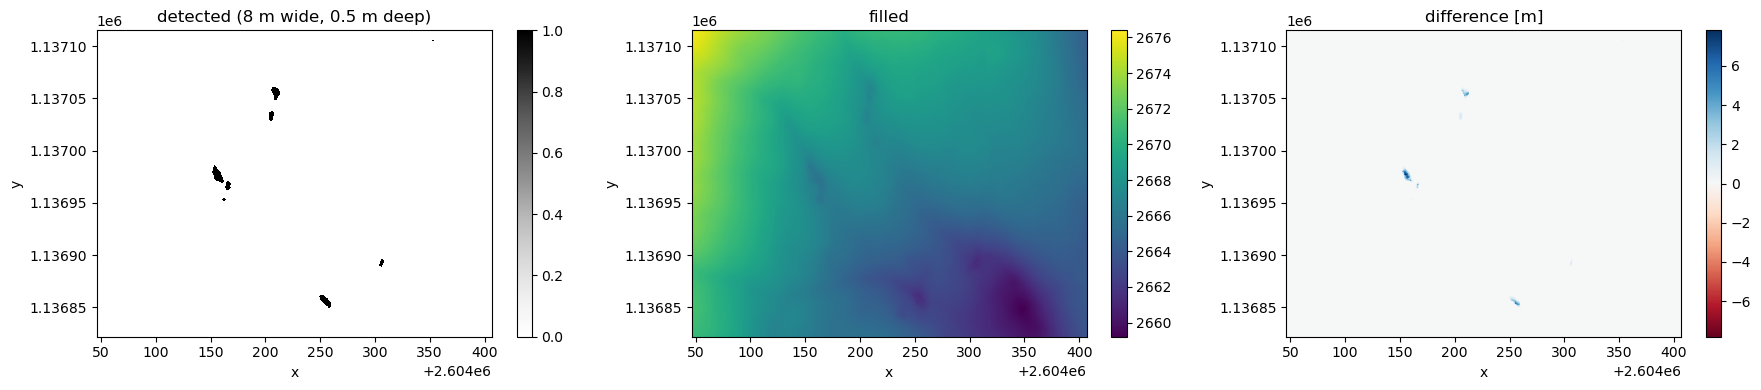

In [6]:
dem, mask = prep_dem(dem_tif, detect_maxsize=8, detect_mindepth=.5)

fig, axs = plt.subplots(1, 3, figsize=(18, 4))
mask.plot(ax=axs[0], cmap='Greys'); axs[0].set_title('detected (8 m wide, 0.5 m deep)')
dem.plot(ax=axs[1]); axs[1].set_title('filled')
(dem - dem_orig).plot(ax=axs[2], cmap='RdBu', center=0); axs[2].set_title('difference [m]')
plt.tight_layout()

## 3. Compare fill methods

- `idw`: inverse distance weighting (rasterio `fillnodata`)
- `laplace` (default): smoothest surface matching the heights at the hole edges
- `biharmonic`: smoothest surface matching heights and slopes at the hole edges, continues the surrounding slope

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(
c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(
c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


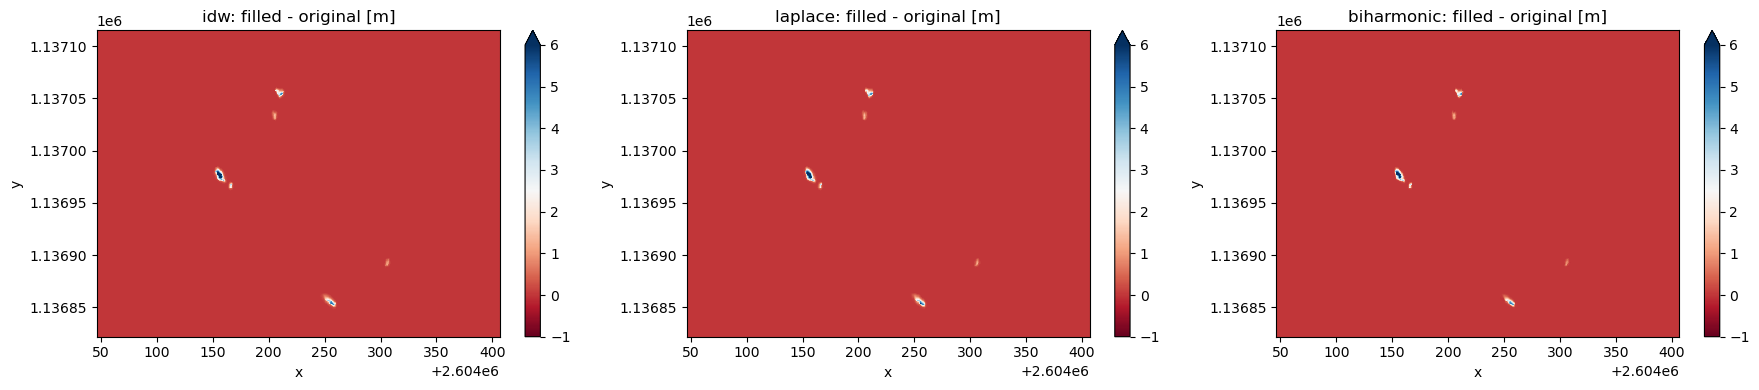

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for ax, method in zip(axs, ['idw', 'laplace', 'biharmonic']):
    dem, mask = prep_dem(dem_tif, fill_mask=moulin_shp, fill_method=method)
    (dem - dem_orig).plot(ax=ax, cmap='RdBu', center=0, vmin=-1, vmax=6)
    ax.set_title(f'{method}: filled - original [m]')
plt.tight_layout()

## 4. Vertical reprojection: LHN95 to WGS84 ellipsoidal heights

The test DEM is assumed to have swiss LHN95 heights (EPSG:5729). For a UAV flying on GNSS heights, they can be converted to WGS84 ellipsoidal heights (EPSG:4979) on the same LV95 grid. PROJ downloads the required geoid grid on first use.

Note: `to_vert_epsg='ellipsoid'` would give heights above the ellipsoid of LV95, which is Bessel 1841, not WGS84.

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


LHN95 -> WGS84 ellipsoid:  +52.32 m
LHN95 -> Bessel ellipsoid: +1.32 m


c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


Text(0.5, 1.0, 'vertical shift LHN95 -> WGS84 ellipsoidal heights [m]')

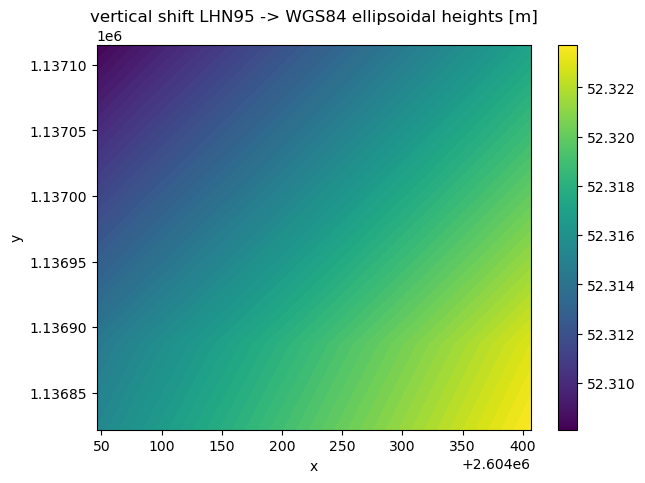

In [8]:
dem_wgs84, _ = prep_dem(dem_tif, from_vert_epsg=5729, to_vert_epsg=4979)
dem_bessel, _ = prep_dem(dem_tif, from_vert_epsg=5729, to_vert_epsg='ellipsoid')

print(f'LHN95 -> WGS84 ellipsoid:  {float((dem_wgs84 - dem_orig).mean()):+.2f} m')
print(f'LHN95 -> Bessel ellipsoid: {float((dem_bessel - dem_orig).mean()):+.2f} m')

(dem_wgs84 - dem_orig).plot(cmap='viridis', figsize=(7, 5))
plt.title('vertical shift LHN95 -> WGS84 ellipsoidal heights [m]')

## 5. Horizontal reprojection

The reprojection runs before all other steps, so distances of the following steps refer to the target CRS. Here the DEM is reprojected to UTM 32N (EPSG:32632) and moulins are detected afterwards.

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


EPSG:32632 (0.49972457235859874, -0.49972457235859874)


Text(0.5, 1.0, 'reprojected to UTM 32N, moulins filled')

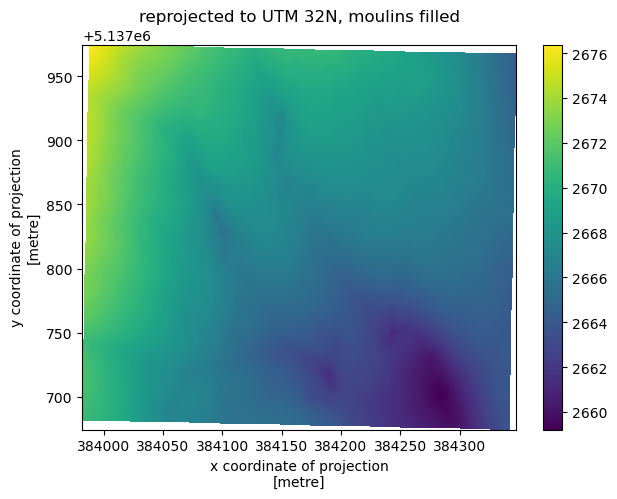

In [9]:
dem_utm, mask_utm = prep_dem(dem_tif, to_horiz_epsg=32632, detect_maxsize=15, detect_mindepth=1)

print(dem_utm.rio.crs, dem_utm.rio.resolution())
dem_utm.plot(figsize=(7, 5))
plt.title('reprojected to UTM 32N, moulins filled')

## 6. Lower level functions

The single steps can also be used separately:
- `reproj_dem` reprojects a rioxarray DataArray horizontally and / or vertically.
- `detect_crevasses` and `inpaint_dem` work on plain numpy arrays. Here, distances are given in **pixels** (0.5 m pixels in the test DEM).

EPSG:4326 2719.568359375


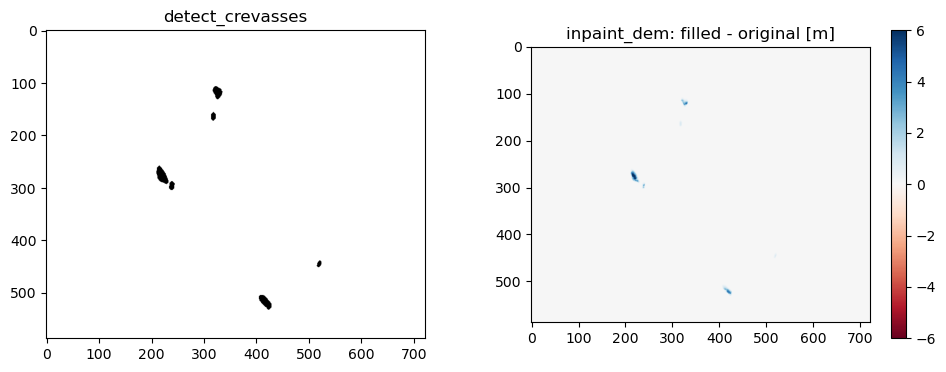

In [10]:
# reproject a DataArray: LV95 grid -> WGS84 lat / lon with WGS84 ellipsoidal heights
dem_latlon = reproj_dem(dem_orig, to_horiz_epsg=4326, from_vert_epsg=5729, to_vert_epsg=4979)
print(dem_latlon.rio.crs, float(dem_latlon.mean()))

# detect and fill on numpy arrays, radius in pixels (15 m / 2 = 7.5 m = 15 px)
data = dem_orig.values
crevasse_mask = detect_crevasses(data, radius=15, depth=1)
filled = inpaint_dem(data, crevasse_mask, method='biharmonic')

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].imshow(crevasse_mask, cmap='Greys'); axs[0].set_title('detect_crevasses')
im = axs[1].imshow(filled - data, cmap='RdBu', vmin=-6, vmax=6); axs[1].set_title('inpaint_dem: filled - original [m]')
plt.colorbar(im, ax=axs[1])

## 7. Save results

With `output_tif`, the prepared DEM is saved with the georeferencing, data type and nodata value of the input. `save_mask=True` also saves the mask of filled pixels as `<output_tif>_mask.tif`.

In [11]:
import os
os.makedirs('output', exist_ok=True)

dem, mask = prep_dem(dem_tif, 'output/dem_prepared.tif', save_mask=True,
                     fill_mask=moulin_shp, detect_maxsize=15, detect_mindepth=1,
                     smoothing_radius=1.5, from_vert_epsg=5729, to_vert_epsg=4979)
print(os.listdir('output'))

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


['dem_prepared.tif', 'dem_prepared_mask.tif']
